## **Cell 1: Imports and config**

In [1]:
%load_ext autoreload
%autoreload 2

import sys, time, json, random
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch.utils.data import DataLoader

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
assert (PROJECT_ROOT / "data").exists(), f"Wrong project root: {PROJECT_ROOT}"
sys.path.insert(0, str(PROJECT_ROOT))

CATEGORY = "metal_nut"
REPORT_DIR = PROJECT_ROOT / "reports" / "metrics"
FIG_DIR    = PROJECT_ROOT / "reports" / "figures"
MODEL_DIR  = PROJECT_ROOT / "models"
for d in (REPORT_DIR, FIG_DIR, MODEL_DIR):
    d.mkdir(parents=True, exist_ok=True)

# ---------- Experiment settings ----------
IMAGE_SIZE    = 256
BATCH_SIZE    = 8
POOL_KERNEL   = 3
SEED          = 42
BANK_RATIO    = 0.10        # coreset fraction used for scoring
SIGMA         = 4.0         # Gaussian smoothing of the anomaly map (kept for baseline; Exp 7 sweeps)

# ---------------- SWITCH ----------------
EMBED_MODE = "baseline"     # "baseline" | "concat"

if EMBED_MODE == "baseline":
    EMBED_DIM  = 1024
    TAG        = "baseline1024"
    EMB_PATH   = MODEL_DIR / f"{CATEGORY}_train_emb_baseline_1024.pt"
    CORESET_PT = MODEL_DIR / f"{CATEGORY}_coreset_indices_baseline1024.pt"
elif EMBED_MODE == "concat":
    EMBED_DIM  = 1536
    TAG        = "concat1536"
    EMB_PATH   = MODEL_DIR / f"{CATEGORY}_train_emb_concat_1536.pt"
    CORESET_PT = MODEL_DIR / f"{CATEGORY}_coreset_indices_concat1536.pt"
else:
    raise ValueError(f"Unknown EMBED_MODE: {EMBED_MODE}")

def seed_everything(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

seed_everything(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"Device     : {device}")
print(f"EMBED_MODE : {EMBED_MODE}")
print(f"EMBED_DIM  : {EMBED_DIM}")
print(f"TAG        : {TAG}")
print(f"EMB_PATH   : {EMB_PATH}  exists={EMB_PATH.exists()}")
print(f"CORESET_PT : {CORESET_PT}  exists={CORESET_PT.exists()}")

Device     : cuda
EMBED_MODE : baseline
EMBED_DIM  : 1024
TAG        : baseline1024
EMB_PATH   : c:\Users\ASUS\Desktop\AI_Projects\Industrial-defect-detection\models\metal_nut_train_emb_baseline_1024.pt  exists=True
CORESET_PT : c:\Users\ASUS\Desktop\AI_Projects\Industrial-defect-detection\models\metal_nut_coreset_indices_baseline1024.pt  exists=True


## **Cell 2: Create src/models/patchcore.py**

In [2]:
OVERWRITE = True

PATCHCORE_CODE = r'''
import torch
import torch.nn.functional as F
import torchvision.transforms.functional as TF

from .feature_extractor import patch_embeddings, patch_embeddings_concat
from .coreset import nn_distance


@torch.inference_mode()
def anomaly_maps(
    extractor,
    bank,
    images,
    embed_dim=1024,
    pool_kernel=3,
    sigma=4.0,
    chunk=512,
    embed_mode="baseline",
):
    """
    images (B, 3, H, W) -> (anomaly_maps (B, H, W), image_scores (B,)).

    patch score = distance to nearest memory-bank patch
    map         = patch scores on the feature grid, upsampled to image size,
                  Gaussian-smoothed (if sigma > 0)
    image score = maximum of the smoothed map (baseline aggregation)
    """
    features = extractor(images)
    if embed_mode == "baseline":
        emb, (h, w) = patch_embeddings(features, embed_dim, pool_kernel)
    else:
        emb, (h, w) = patch_embeddings_concat(features, pool_kernel)

    b, p, d = emb.shape
    dist = nn_distance(emb.reshape(b * p, d), bank, chunk)

    maps = dist.reshape(b, 1, h, w)
    maps = F.interpolate(
        maps, size=images.shape[-2:], mode="bilinear", align_corners=False
    )

    if sigma > 0:
        k = 2 * int(4 * sigma + 0.5) + 1
        maps = TF.gaussian_blur(maps, kernel_size=[k, k], sigma=[sigma, sigma])

    maps = maps.squeeze(1)
    scores = maps.flatten(1).max(dim=1).values
    return maps, scores


@torch.inference_mode()
def score_loader(extractor, bank, loader, device, **kw):
    """
    Score a whole DataLoader.
    Returns a dict of CPU tensors / Python lists in loader order.
    """
    maps, scores, labels, masks, types, paths = [], [], [], [], [], []
    for batch in loader:
        x = batch["image"].to(device, non_blocking=True)
        m, s = anomaly_maps(extractor, bank, x, **kw)
        maps.append(m.cpu())
        scores.append(s.cpu())
        labels.append(batch["label"])
        masks.append(batch["mask"][:, 0])
        types += list(batch["defect_type"])
        paths += list(batch["path"])
    return dict(
        maps=torch.cat(maps),
        scores=torch.cat(scores),
        labels=torch.cat(labels),
        masks=torch.cat(masks),
        defect_types=types,
        paths=paths,
    )
'''

path = PROJECT_ROOT / "src" / "models" / "patchcore.py"
path.parent.mkdir(parents=True, exist_ok=True)
if path.exists() and not OVERWRITE:
    print("kept   :", path.relative_to(PROJECT_ROOT))
else:
    path.write_text(PATCHCORE_CODE, encoding="utf-8")
    print("written:", path.relative_to(PROJECT_ROOT))

written: src\models\patchcore.py


## **Cell 3: Force Reload + Imports + Load Splits**

In [3]:
import sys

for mod_name in ["src", "src.data", "src.data.dataset",
                 "src.models", "src.models.feature_extractor",
                 "src.models.coreset", "src.models.patchcore"]:
    if mod_name in sys.modules:
        del sys.modules[mod_name]

sys.path.insert(0, str(PROJECT_ROOT))
import src
assert Path(src.__file__).resolve().is_relative_to(PROJECT_ROOT.resolve())

from src.data.dataset import MVTecDataset, load_splits, IMAGENET_MEAN, IMAGENET_STD
from src.models.feature_extractor import (
    FeatureExtractor, extract_dataset, extract_dataset_concat, patch_embeddings_concat
)
from src.models.patchcore import anomaly_maps, score_loader

splits = load_splits(REPORT_DIR / f"{CATEGORY}_splits.csv", PROJECT_ROOT)
train_fit  = splits[splits.role == "fit"]
val_normal = splits[splits.role == "val_normal"]
test_df    = splits[splits.role == "test"]

assert (len(train_fit), len(val_normal), len(test_df)) == (198, 22, 115), \
    "Unexpected split sizes"
print("fit / val_normal / test:", len(train_fit), "/", len(val_normal), "/", len(test_df))

def make_loader(df):
    return DataLoader(
        MVTecDataset(df, IMAGE_SIZE),
        batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=True,
    )

# We also need test_ds for visualization later
test_ds = MVTecDataset(test_df, IMAGE_SIZE)

fit / val_normal / test: 198 / 22 / 115


## **Cell 4: Load Pre-Computed Train Embeddings + Rebuild the Bank**

In [4]:
# ---------- Load coreset checkpoint ----------
ckpt = torch.load(CORESET_PT)
assert ckpt["embed_mode"] == EMBED_MODE, \
    f"Mismatched coreset mode: {ckpt['embed_mode']} vs {EMBED_MODE}"
assert ckpt["embed_dim"]  == EMBED_DIM,  \
    f"Mismatched embedding dim: {ckpt['embed_dim']} vs {EMBED_DIM}"
assert ckpt["seed"] == SEED, "Seed mismatch"

# ---------- Load training embeddings saved by Exp 3 ----------
train_emb = torch.load(EMB_PATH)
assert train_emb.shape[-1] == EMBED_DIM

flat = train_emb.reshape(-1, EMBED_DIM)
assert flat.shape[0] == ckpt["n_total_patches"], \
    f"Patch count changed since coreset was saved: {flat.shape[0]} vs {ckpt['n_total_patches']}"

n_bank = int(BANK_RATIO * flat.shape[0])
bank = flat[ckpt["indices"][:n_bank]].to(device)
del train_emb, flat

print(f"mode        : {EMBED_MODE} (dim={EMBED_DIM})")
print(f"memory bank : {tuple(bank.shape)} = {bank.numel() * 4 / 1e6:.1f} MB")
print(f"bank ratio  : {BANK_RATIO} ({n_bank} patches)")

mode        : baseline (dim=1024)
memory bank : (20275, 1024) = 83.0 MB
bank ratio  : 0.1 (20275 patches)


## **Cell 5: Score Test + Held-Out Normals (With Warmup + Reliable Timing)**

In [5]:
KW = dict(
    embed_dim=EMBED_DIM,
    pool_kernel=POOL_KERNEL,
    sigma=SIGMA,
    embed_mode=EMBED_MODE,
)

extractor = FeatureExtractor().to(device)

test_loader = make_loader(test_df)
val_loader  = make_loader(val_normal)

# ---------- Warmup (3 passes, not timed) ----------
for _ in range(3):
    _ = score_loader(extractor, bank, test_loader, device, **KW)

# ---------- Timed run ----------
if device.type == "cuda":
    torch.cuda.synchronize()
torch.cuda.reset_peak_memory_stats()

t0 = time.perf_counter()
res_test = score_loader(extractor, bank, test_loader, device, **KW)
if device.type == "cuda":
    torch.cuda.synchronize()
dt = time.perf_counter() - t0

latency_ms = 1000 * dt / len(test_df)
peak_mb    = torch.cuda.max_memory_allocated() / 1e6

res_val = score_loader(extractor, bank, val_loader, device, **KW)

print("test maps            :", tuple(res_test["maps"].shape))
print(f"test set             : {dt:.2f} s total = {latency_ms:.1f} ms/image")
print(f"(feature extraction + search + smoothing, data loading included)")
print(f"peak GPU memory (MB) : {peak_mb:.1f}")

test maps            : (115, 256, 256)
test set             : 5.56 s total = 48.4 ms/image
(feature extraction + search + smoothing, data loading included)
peak GPU memory (MB) : 431.6


## **Cell 6: Score Aggregation Comparison**

In [6]:
from sklearn.metrics import roc_auc_score, average_precision_score

# Get the smoothed anomaly maps (already computed in res_test)
maps_test = res_test["maps"]                                  # (N, H, W)
labels_np = res_test["labels"].numpy()
t_test    = np.array(res_test["defect_types"])
flat_maps = maps_test.reshape(maps_test.shape[0], -1)         # (N, H*W)

# --- Aggregation strategies ---
score_max     = flat_maps.max(dim=1).values
k_1pct        = max(1, int(0.01  * flat_maps.shape[1]))
k_01pct       = max(1, int(0.001 * flat_maps.shape[1]))
score_top1pct = flat_maps.topk(k_1pct,  dim=1).values.mean(dim=1)
score_top01pct= flat_maps.topk(k_01pct, dim=1).values.mean(dim=1)
score_p995    = torch.quantile(flat_maps, 0.995, dim=1)

agg_rows = []
for name, sc in [
    ("max",              score_max),
    ("top 1% mean",      score_top1pct),
    ("top 0.1% mean",    score_top01pct),
    ("99.5th percentile",score_p995),
]:
    sc_np = sc.numpy()
    agg_rows.append({
        "aggregation": name,
        "image_auroc": round(roc_auc_score(labels_np, sc_np), 4),
        "image_ap":    round(average_precision_score(labels_np, sc_np), 4),
    })

agg_df = pd.DataFrame(agg_rows)
print("Image-level score aggregation comparison:")
print(agg_df.to_string(index=False))
agg_df.to_csv(REPORT_DIR / f"{CATEGORY}_score_aggregation_{TAG}.csv", index=False)

# Per-defect AUROC for the two best aggregations (usually max + top-1%)
print("\nPer-defect AUROC (max vs top 1%):")
print(f"  {'defect':10s} {'max':>8s} {'top 1%':>8s}")
for d in ["bent", "color", "flip", "scratch"]:
    m = (t_test == d) | (t_test == "good")
    a_max   = roc_auc_score(labels_np[m], score_max.numpy()[m])
    a_top1  = roc_auc_score(labels_np[m], score_top1pct.numpy()[m])
    print(f"  {d:10s} {a_max:8.4f} {a_top1:8.4f}")

Image-level score aggregation comparison:
      aggregation  image_auroc  image_ap
              max       0.9995    0.9999
      top 1% mean       0.9980    0.9995
    top 0.1% mean       0.9990    0.9998
99.5th percentile       0.9980    0.9995

Per-defect AUROC (max vs top 1%):
  defect          max   top 1%
  bent         1.0000   0.9964
  color        1.0000   1.0000
  flip         1.0000   1.0000
  scratch      0.9980   0.9960


## **Cell 7: Score Statistics + Provisional Threshold**

In [7]:
# --- Use the max aggregation as the baseline score (matches Exp 5 baseline) ---
s_val  = res_val["scores"].numpy()        # held-out normals
s_test = score_max.numpy()                # from Cell 6 (equivalent to res_test["scores"])
y_test = labels_np

THRESH = float(s_val.max())                # provisional: highest normal score

print(f"held-out normal (n={len(s_val)}): "
      f"mean {s_val.mean():.3f} | std {s_val.std():.3f} | max {s_val.max():.3f}")
print(f"provisional threshold = {THRESH:.3f}\n")

rows = []
for g in ["good", "bent", "color", "flip", "scratch"]:
    s = s_test[t_test == g]
    rows.append(dict(
        group=g, n=len(s),
        mean=round(float(s.mean()), 3),
        min=round(float(s.min()), 3),
        max=round(float(s.max()), 3),
        flagged_above_threshold=int((s > THRESH).sum()),
    ))
thr_df = pd.DataFrame(rows)
print(thr_df.to_string(index=False))
thr_df.to_csv(REPORT_DIR / f"{CATEGORY}_score_stats_{TAG}.csv", index=False)

held-out normal (n=22): mean 1.062 | std 0.067 | max 1.167
provisional threshold = 1.167

  group  n  mean   min   max  flagged_above_threshold
   good 22 1.068 0.930 1.246                        2
   bent 25 1.594 1.250 1.812                       25
  color 22 1.587 1.280 1.872                       22
   flip 23 1.790 1.710 1.909                       23
scratch 23 1.510 1.233 1.688                       23


## **Cell 8: Score Distribution Plot**

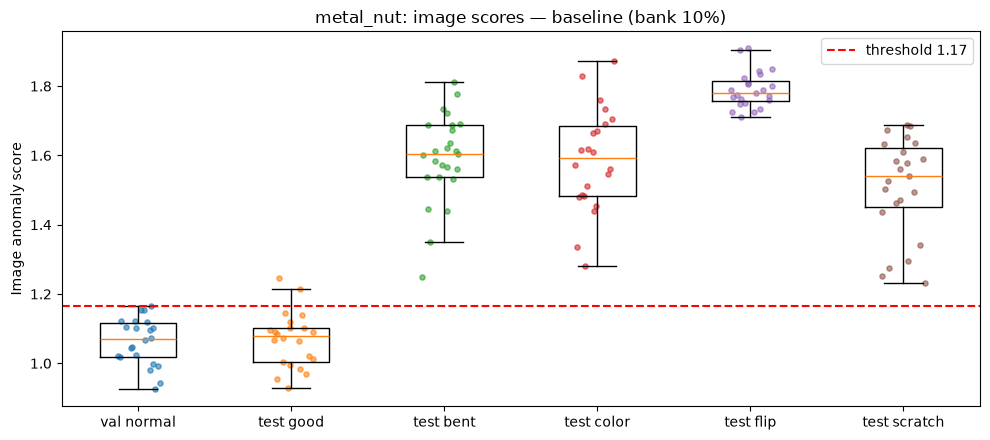

In [8]:
groups = {"val normal": s_val}
for g in ["good", "bent", "color", "flip", "scratch"]:
    groups[f"test {g}"] = s_test[t_test == g]

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.boxplot(list(groups.values()), showfliers=False)
ax.set_xticks(range(1, len(groups) + 1), labels=list(groups.keys()))
rng = np.random.default_rng(SEED)
for i, v in enumerate(groups.values(), start=1):
    ax.scatter(i + rng.uniform(-0.15, 0.15, len(v)), v, s=14, alpha=0.6)
ax.axhline(THRESH, color="red", linestyle="--", label=f"threshold {THRESH:.2f}")
ax.set_ylabel("Image anomaly score")
ax.set_title(f"{CATEGORY}: image scores — {EMBED_MODE} (bank {int(BANK_RATIO*100)}%)")
ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / f"{CATEGORY}_score_dist_{TAG}.png", dpi=150)
plt.show()

## **Cell 9: Heatmap Visualization (Change C — 5 Case Types)**

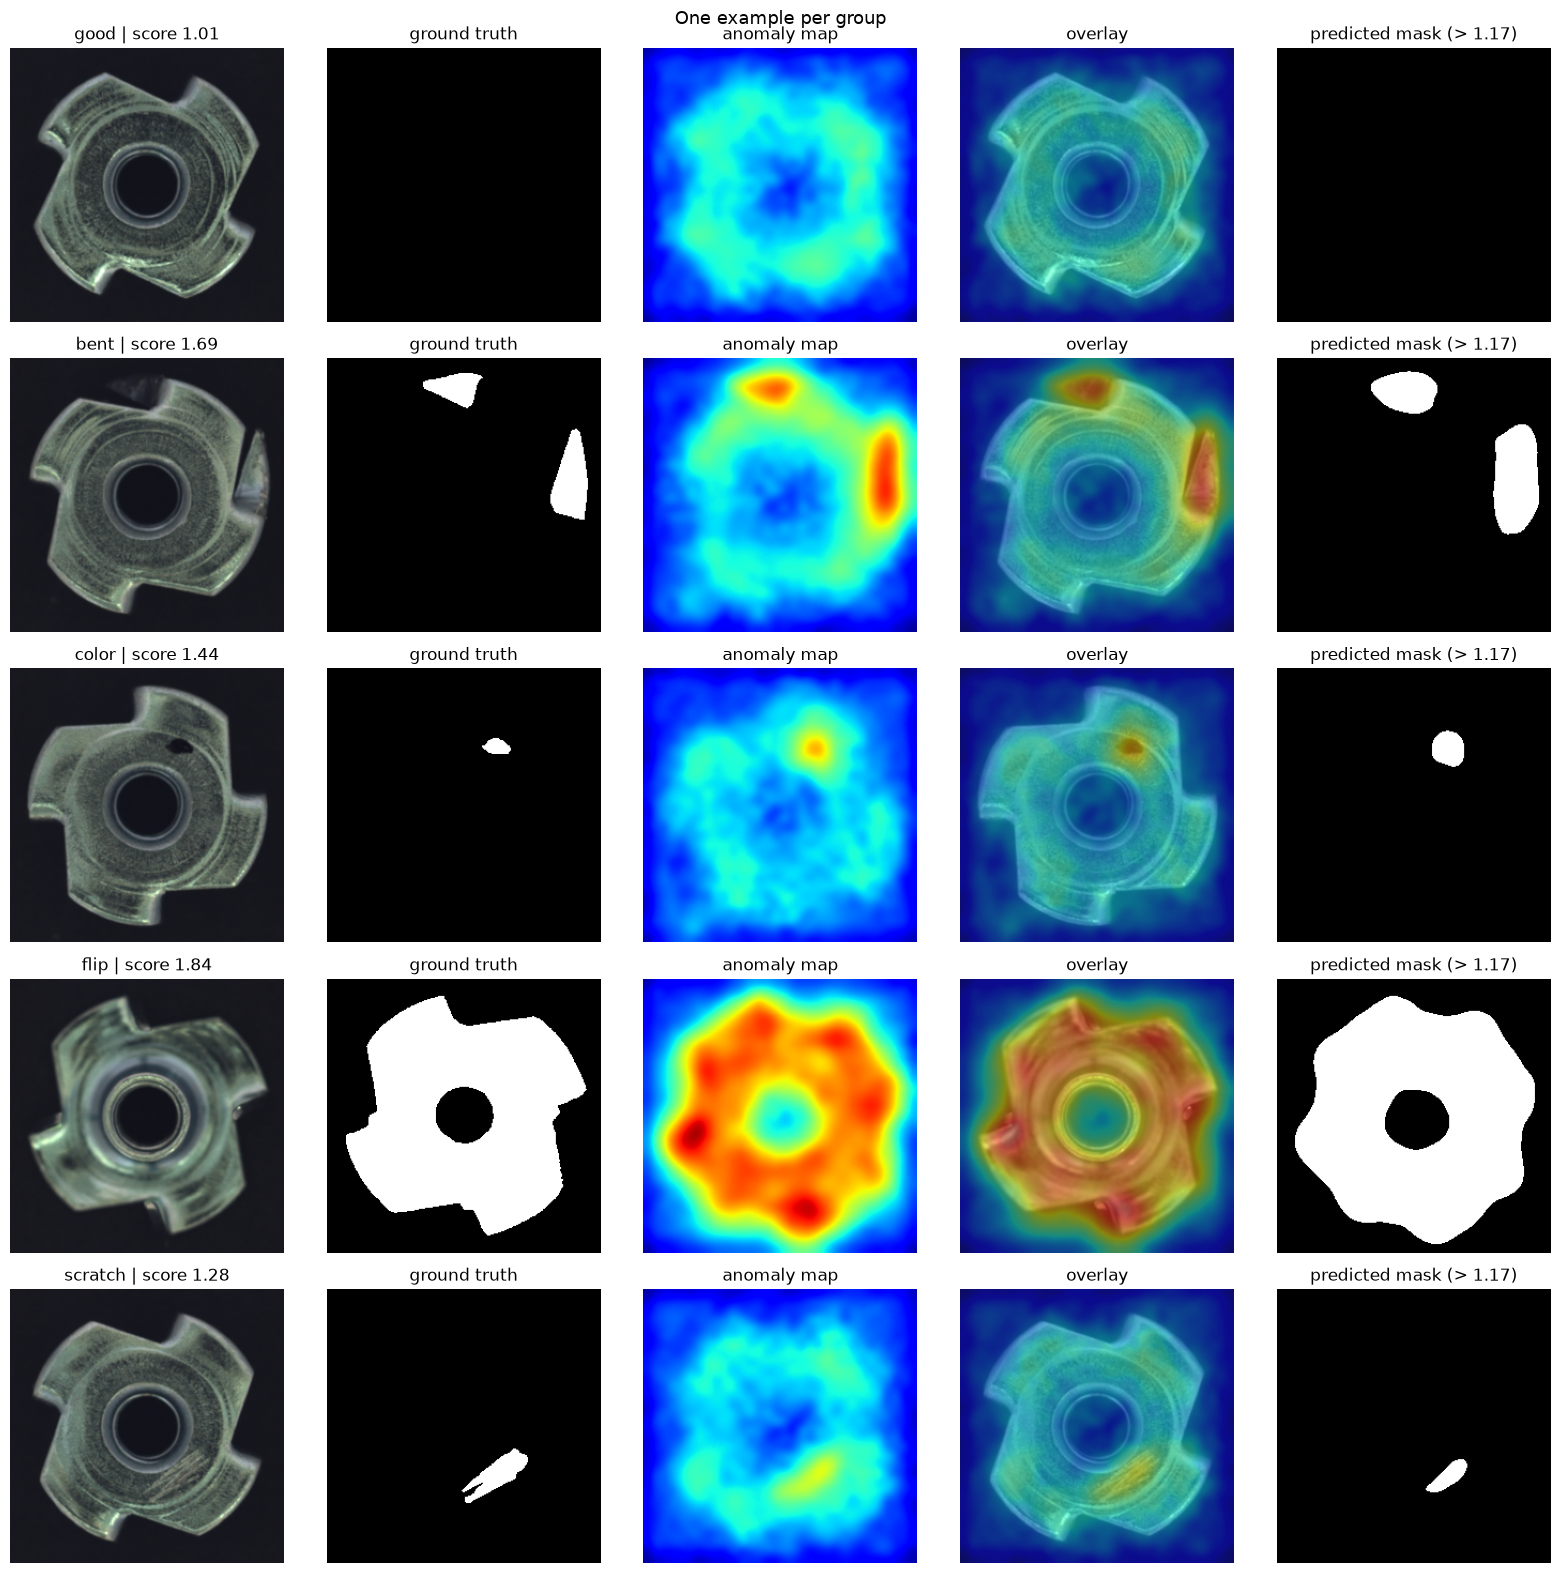

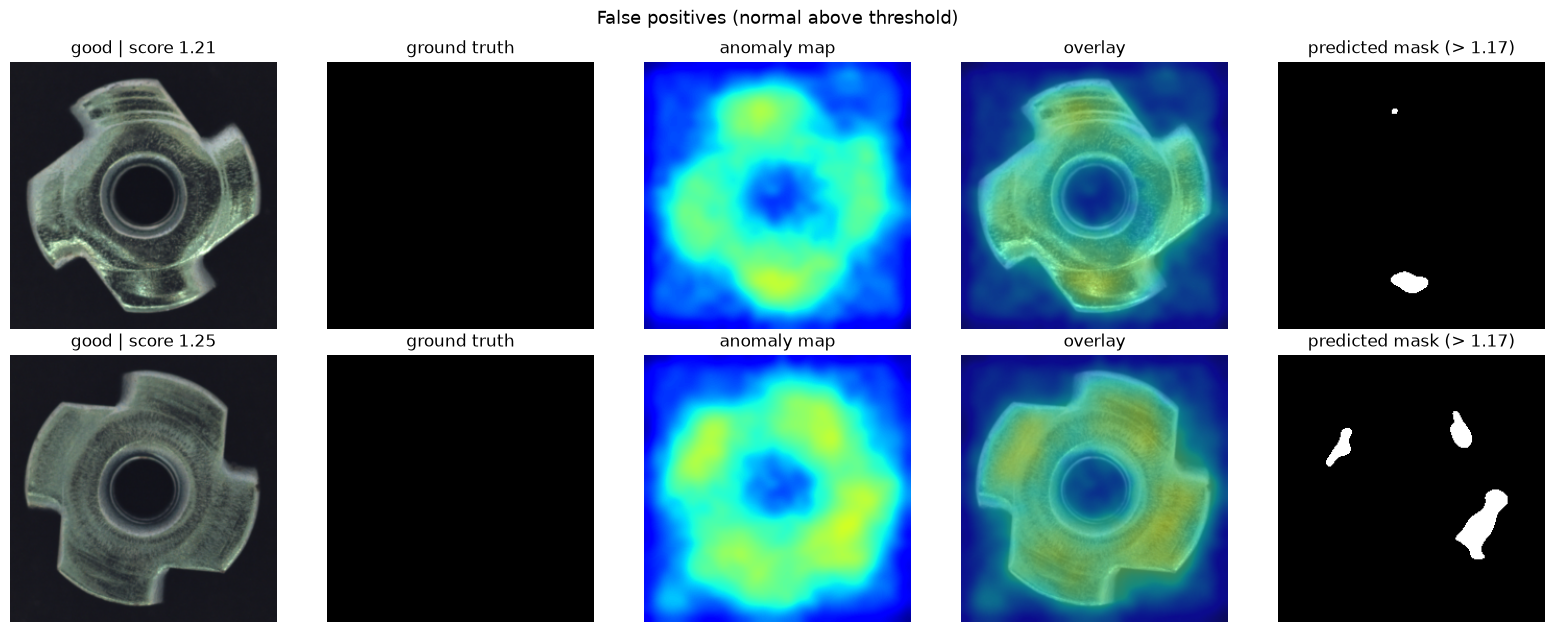

[Misses (defective below threshold)] no cases to show


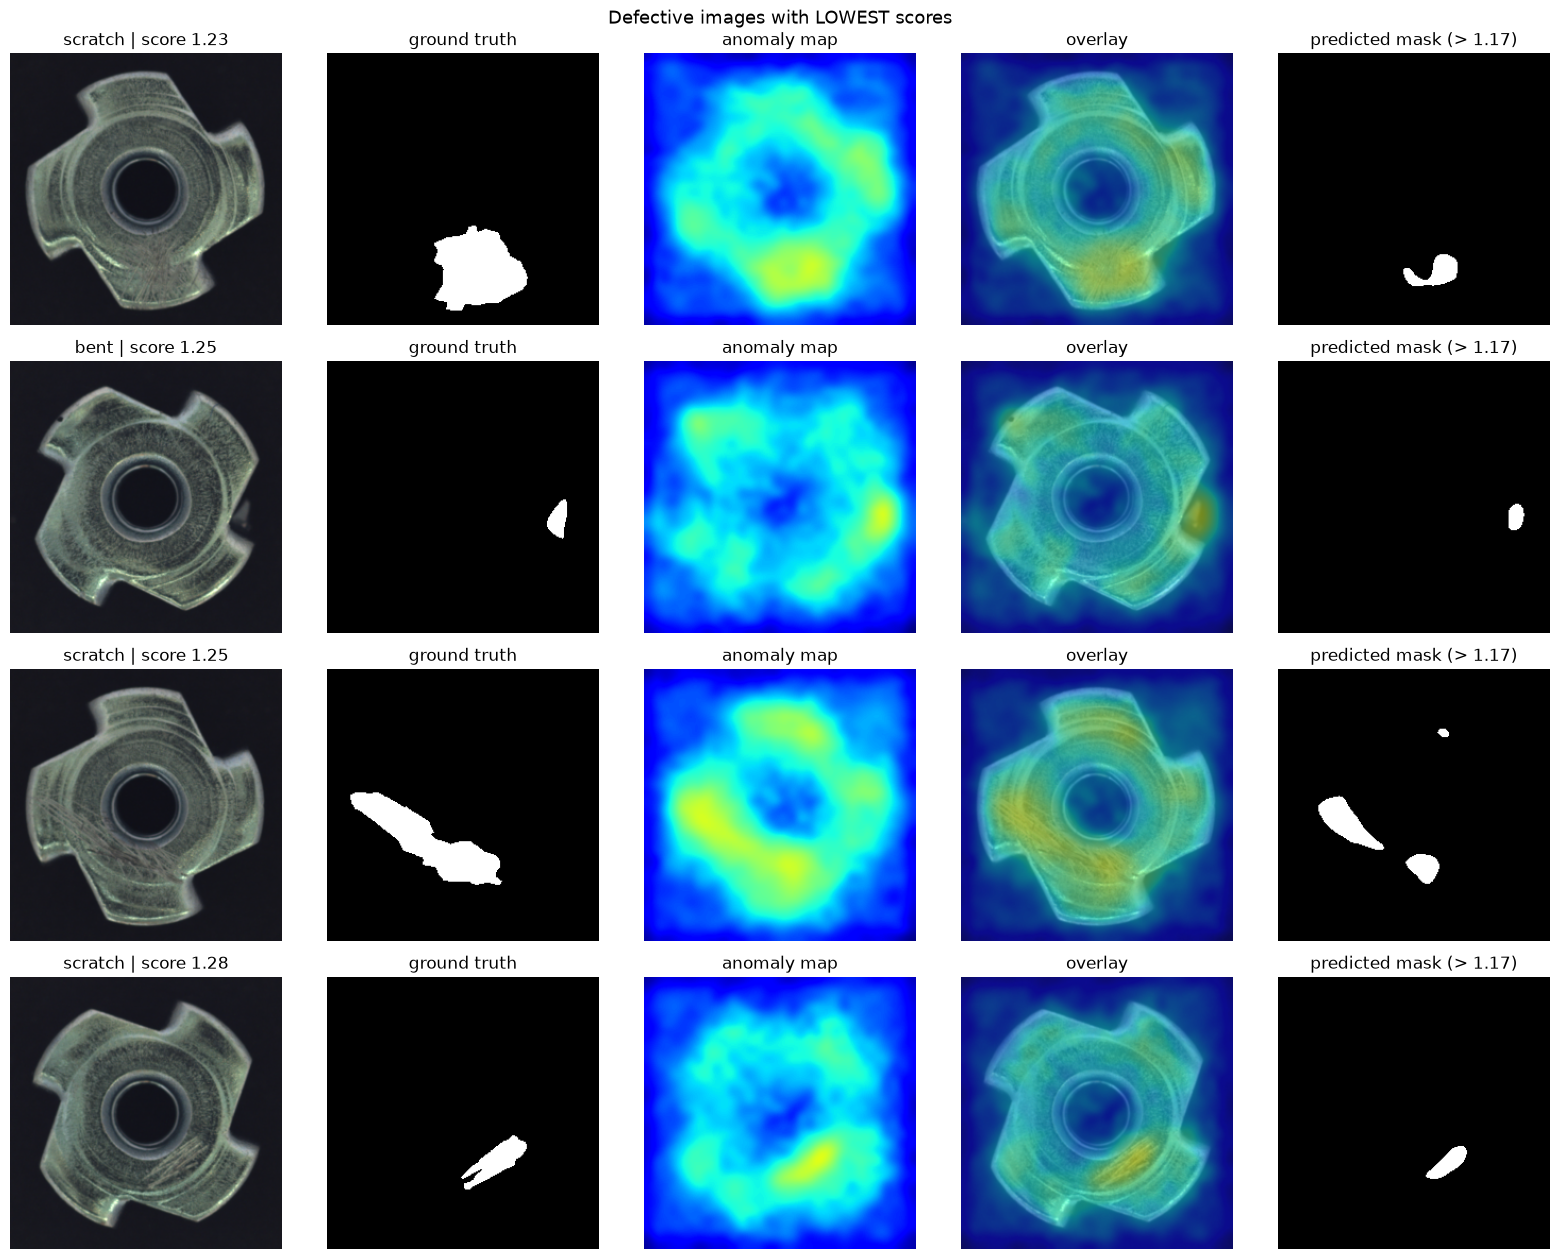

In [9]:
mean = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
std  = torch.tensor(IMAGENET_STD).view(3, 1, 1)

def denorm(t):
    return (t * std + mean).clamp(0, 1).permute(1, 2, 0).numpy()

vmin = float(res_test["maps"].min())
vmax = float(res_test["maps"].max())

def show_cases(indices, title, fname):
    if len(indices) == 0:
        print(f"[{title}] no cases to show")
        return
    fig, axes = plt.subplots(len(indices), 5,
                             figsize=(16, 3.2 * len(indices)))
    axes = np.atleast_2d(axes)
    for row, i in zip(axes, indices):
        img  = denorm(test_ds[i]["image"])
        gt   = res_test["masks"][i].numpy()
        amap = res_test["maps"][i].numpy()
        pred = amap > THRESH
        row[0].imshow(img);  row[0].set_title(
            f"{res_test['defect_types'][i]} | score {s_test[i]:.2f}")
        row[1].imshow(gt, cmap="gray");  row[1].set_title("ground truth")
        row[2].imshow(amap, cmap="jet", vmin=vmin, vmax=vmax)
        row[2].set_title("anomaly map")
        row[3].imshow(img); row[3].imshow(amap, cmap="jet", alpha=0.5,
                                            vmin=vmin, vmax=vmax)
        row[3].set_title("overlay")
        row[4].imshow(pred, cmap="gray")
        row[4].set_title(f"predicted mask (> {THRESH:.2f})")
        for a in row: a.axis("off")
    fig.suptitle(title, fontsize=13)
    plt.tight_layout()
    plt.savefig(FIG_DIR / fname, dpi=130)
    plt.show()

# --- 1. One example per defect group ---
def first_idx(g):
    hits = np.where(t_test == g)[0]
    return int(hits[0]) if len(hits) else None

per_group = [first_idx(g) for g in ["good", "bent", "color", "flip", "scratch"]]
per_group = [i for i in per_group if i is not None]
show_cases(per_group, "One example per group",
           f"{CATEGORY}_heatmap_examples_{TAG}.png")

# --- 2. False positives (normal images above threshold) ---
fp_idx = np.where((y_test == 0) & (s_test > THRESH))[0]
show_cases(list(fp_idx), "False positives (normal above threshold)",
           f"{CATEGORY}_false_positives_{TAG}.png")

# --- 3. Misses (defective below threshold) ---
fn_idx = np.where((y_test == 1) & (s_test <= THRESH))[0]
show_cases(list(fn_idx), "Misses (defective below threshold)",
           f"{CATEGORY}_misses_{TAG}.png")

# --- 4. Lowest-scoring defects (hardest to detect) ---
defect_idx = np.where(y_test == 1)[0]
worst = defect_idx[np.argsort(s_test[defect_idx])[:4]]
show_cases(list(worst), "Defective images with LOWEST scores",
           f"{CATEGORY}_lowest_scoring_defects_{TAG}.png")

## **Cell 10: Save Scores + Run Metadata**

In [10]:
# --- Scores CSV ---
out = pd.DataFrame({
    "path":        [Path(p).relative_to(PROJECT_ROOT).as_posix() for p in res_test["paths"]],
    "defect_type": res_test["defect_types"],
    "label":       y_test,
    "score":       s_test,
})
out.to_csv(REPORT_DIR / f"{CATEGORY}_scores_{TAG}.csv", index=False)

pd.DataFrame({"score": s_val}).to_csv(
    REPORT_DIR / f"{CATEGORY}_val_normal_scores_{TAG}.csv", index=False
)

# --- Run metadata ---
meta = {
    "category":           CATEGORY,
    "embed_mode":         EMBED_MODE,
    "embed_dim":          EMBED_DIM,
    "image_size":         IMAGE_SIZE,
    "pool_kernel":        POOL_KERNEL,
    "bank_ratio":         BANK_RATIO,
    "n_bank_patches":     int(bank.shape[0]),
    "sigma":              SIGMA,
    "score_aggregation":  "max",
    "threshold":          float(THRESH),
    "threshold_policy":   "max of held-out normal image scores (n=22)",
    "test_latency_ms":    round(latency_ms, 2),
    "peak_gpu_mb":        round(peak_mb, 1),
    "torch":              torch.__version__,
    "seed":               SEED,
}
with open(REPORT_DIR / f"{CATEGORY}_scoring_meta_{TAG}.json", "w") as f:
    json.dump(meta, f, indent=2)

print(json.dumps(meta, indent=2))
print(f"\nSaved score files for {TAG}.")

{
  "category": "metal_nut",
  "embed_mode": "baseline",
  "embed_dim": 1024,
  "image_size": 256,
  "pool_kernel": 3,
  "bank_ratio": 0.1,
  "n_bank_patches": 20275,
  "sigma": 4.0,
  "score_aggregation": "max",
  "threshold": 1.16659677028656,
  "threshold_policy": "max of held-out normal image scores (n=22)",
  "test_latency_ms": 48.38,
  "peak_gpu_mb": 431.6,
  "torch": "2.7.1+cu118",
  "seed": 42
}

Saved score files for baseline1024.
